# Air Quality Index (AQI) Prediction – India 2015–2020

**AICTE Cycle-4 internship project.** Predict the daily **AQI** of Indian cities from pollutant concentrations, using machine learning.

**Pipeline:** load data → clean → explore → train/test split → impute and scale (fitted on the training set only) → compare 5 regressors → check on unseen years → feature importance → AQI-category accuracy.

| | |
|---|---|
| Dataset | `data/city_day.csv`: 29,531 daily records, 26 cities, 2015-01-01 → 2020-07-01 |
| Features | PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene (+ month) |
| Target | `AQI` (regression). `AQI_Bucket` is derived from it and used for evaluation only |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load and inspect the data

In [2]:
df = pd.read_csv("data/city_day.csv", parse_dates=["Date"])
print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
missing = (df.isna().mean() * 100).sort_values(ascending=False).round(1)
missing.to_frame("% missing")

,% missing
Xylene,61.3
PM10,37.7
NH3,35.0
Toluene,27.2
Benzene,19.0
AQI,15.9
AQI_Bucket,15.9
PM2.5,15.6
NOx,14.2
O3,13.6


**Observations**
- `AQI` (and so `AQI_Bucket`) is missing for about 16 % of rows. Those rows can't be used to train or evaluate a model, so they are dropped.
- Xylene is missing about 61 % of the time, PM10 about 38 % and NH3 about 35 %. These gaps are filled with the **training-set median** inside the model pipeline. Filling them using statistics from the whole dataset would leak test information.
- There are no duplicate rows.

In [4]:
print("duplicates:", df.duplicated().sum())
df = df.dropna(subset=["AQI"]).reset_index(drop=True)
print("rows with AQI:", len(df))
POLLUTANTS = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3",
              "Benzene", "Toluene", "Xylene"]
df[POLLUTANTS + ["AQI"]].describe().T.round(2)

duplicates: 0
rows with AQI: 24850


,count,mean,std,min,25%,50%,75%,max
PM2.5,24172.0,67.48,63.08,0.04,29.00,48.78,80.92,914.94
PM10,17764.0,118.45,89.49,0.03,56.78,96.18,150.18,917.08
NO,24463.0,17.62,22.42,0.03,5.66,9.91,20.03,390.68
NO2,24459.0,28.98,24.63,0.01,11.94,22.10,38.24,362.21
NOx,22993.0,32.29,30.71,0.00,13.11,23.68,40.17,378.24
NH3,18314.0,23.85,25.88,0.01,8.96,16.31,30.36,352.89
CO,24405.0,2.35,7.08,0.00,0.59,0.93,1.48,175.81
SO2,24245.0,14.36,17.43,0.01,5.73,9.22,15.14,186.08
O3,24043.0,34.91,21.72,0.01,19.25,31.25,46.08,257.73
Benzene,21315.0,3.46,16.04,0.00,0.23,1.29,3.34,455.03


## 2. Exploratory data analysis

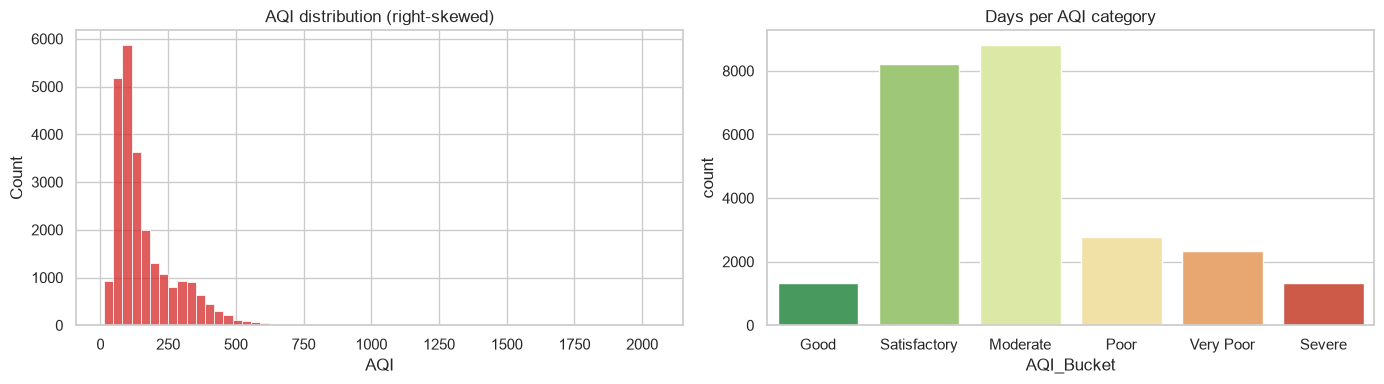

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["AQI"], bins=60, ax=ax[0], color="tab:red")
ax[0].set_title("AQI distribution (right-skewed)")
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
sns.countplot(x="AQI_Bucket", data=df, order=order, ax=ax[1], palette="RdYlGn_r")
ax[1].set_title("Days per AQI category")
plt.tight_layout(); plt.show()

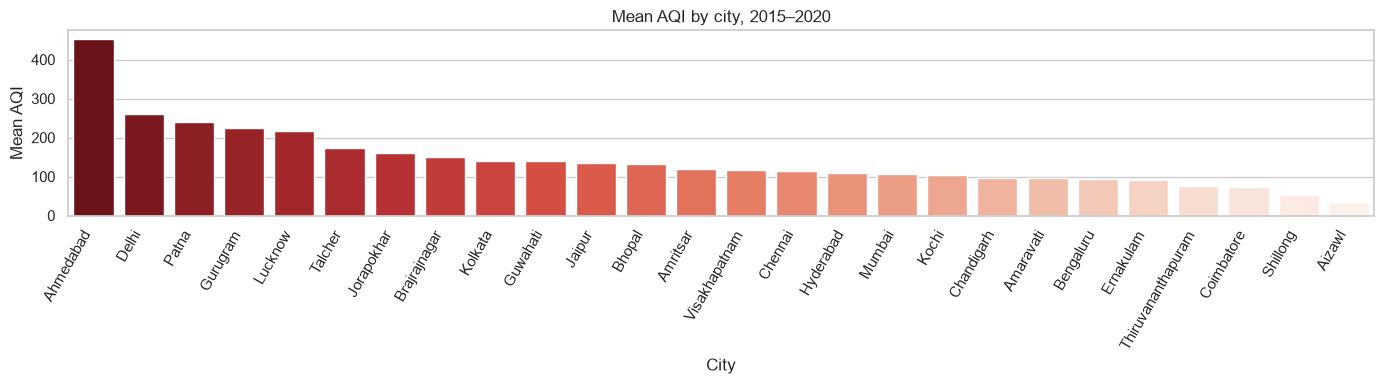

City
Ahmedabad    452.1
Delhi        259.5
Patna        240.8
Gurugram     225.1
Lucknow      218.0
Name: AQI, dtype: float64

In [6]:
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)
plt.figure(figsize=(14, 4))
sns.barplot(x=city_aqi.index, y=city_aqi.values, palette="Reds_r")
plt.xticks(rotation=60, ha="right"); plt.ylabel("Mean AQI"); plt.title("Mean AQI by city, 2015–2020")
plt.tight_layout(); plt.show()
city_aqi.head(5).round(1)

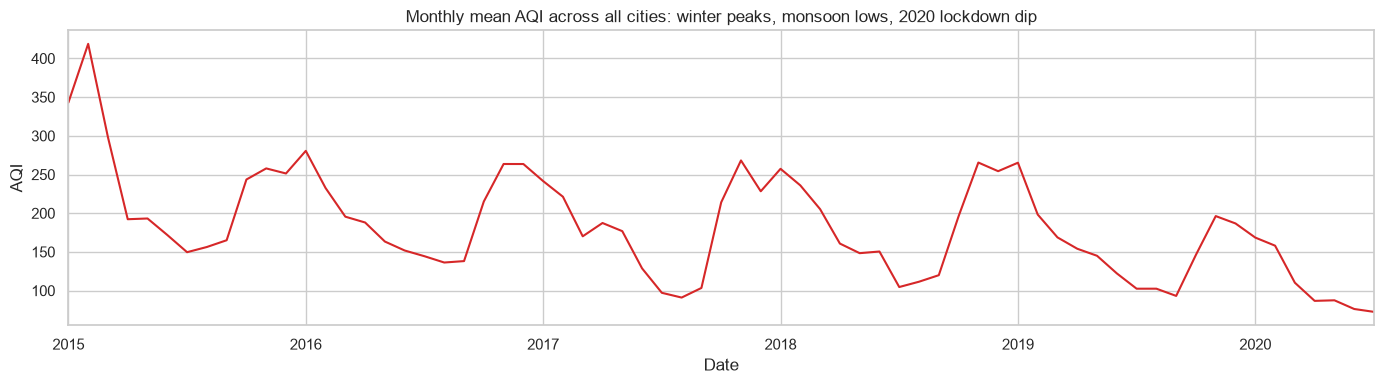

In [7]:
monthly = df.set_index("Date")["AQI"].resample("MS").mean()
plt.figure(figsize=(14, 4))
monthly.plot(color="tab:red")
plt.title("Monthly mean AQI across all cities: winter peaks, monsoon lows, 2020 lockdown dip")
plt.ylabel("AQI"); plt.tight_layout(); plt.show()

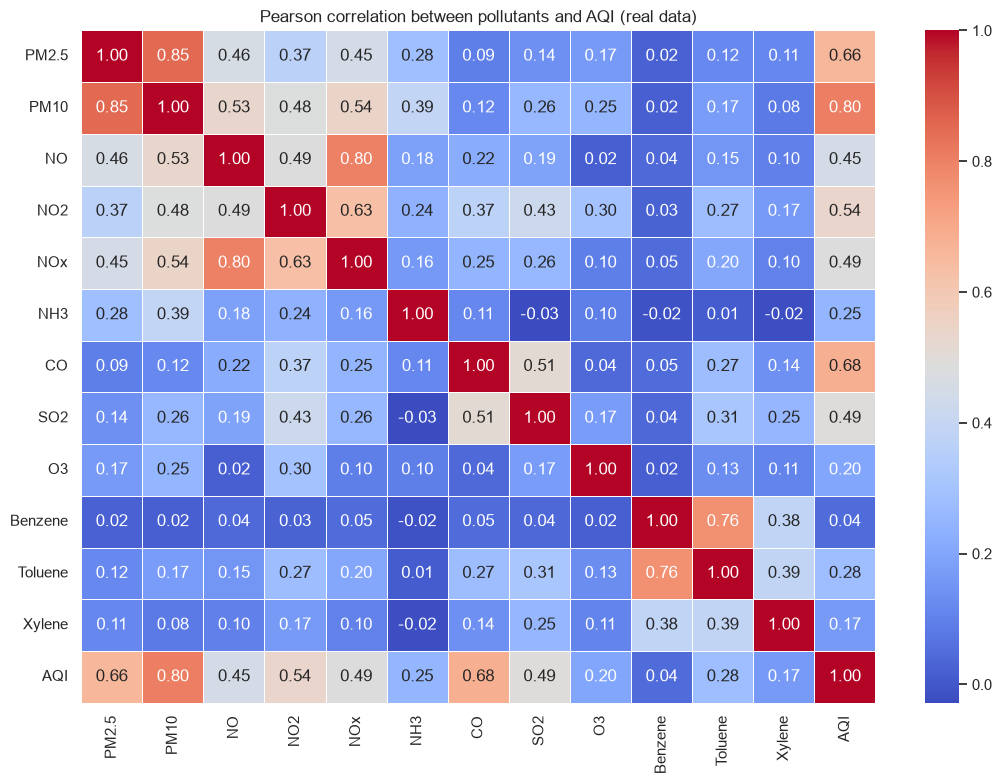

In [8]:
plt.figure(figsize=(11, 8))
sns.heatmap(df[POLLUTANTS + ["AQI"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Pearson correlation between pollutants and AQI (real data)")
plt.tight_layout(); plt.show()

**Takeaways:** PM10 (r ≈ 0.80), CO (0.68) and PM2.5 (0.66) correlate most strongly with AQI. That fits the CPCB AQI definition, where the AQI is set by the worst sub-index, usually particulate matter. AQI is highest in North-Indian cities (Ahmedabad, Delhi, Patna, Gurugram, Lucknow) and follows a clear seasonal cycle.

## 3. Features and train/test split

- Features: the 12 pollutants plus `Month`, which captures seasonality. `City` is left out so the model works for any location.
- **Random 80/20 split** for the main comparison.
- **Outliers are not removed or clipped.** Extreme pollution days are real and matter most. Clipping the *target*, as the earlier version did, hides exactly the days we want to predict.

In [9]:
df["Month"] = df["Date"].dt.month
FEATURES = POLLUTANTS + ["Month"]
X, y = df[FEATURES], df["AQI"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("train:", X_train.shape, " test:", X_test.shape)

train: (19880, 13)  test: (4970, 13)


## 4. Model comparison

In [10]:
def impute():
    return SimpleImputer(strategy="median")

models = {
    "Linear Regression": make_pipeline(impute(), StandardScaler(), LinearRegression()),
    "KNN (k=7)": make_pipeline(impute(), StandardScaler(), KNeighborsRegressor(n_neighbors=7)),
    "Decision Tree": make_pipeline(impute(), DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE)),
    "Random Forest": make_pipeline(impute(), RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                                     n_jobs=-1, random_state=RANDOM_STATE)),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.08,
                                                            random_state=RANDOM_STATE),  # handles NaN natively
}

def evaluate(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    return {
        "Train R²": r2_score(ytr, p_tr),
        "Test R²": r2_score(yte, p_te),
        "Test RMSE": mean_squared_error(yte, p_te) ** 0.5,
        "Test MAE": mean_absolute_error(yte, p_te),
    }

results = pd.DataFrame({name: evaluate(m, X_train, y_train, X_test, y_test) for name, m in models.items()}).T
results = results.sort_values("Test R²", ascending=False)
results.round(3)

,Train R²,Test R²,Test RMSE,Test MAE
Random Forest,0.975,0.908,41.067,20.709
Hist Gradient Boosting,0.948,0.903,42.137,21.208
KNN (k=7),0.912,0.883,46.339,23.781
Decision Tree,0.970,0.851,52.156,24.958
Linear Regression,0.858,0.807,59.449,31.185


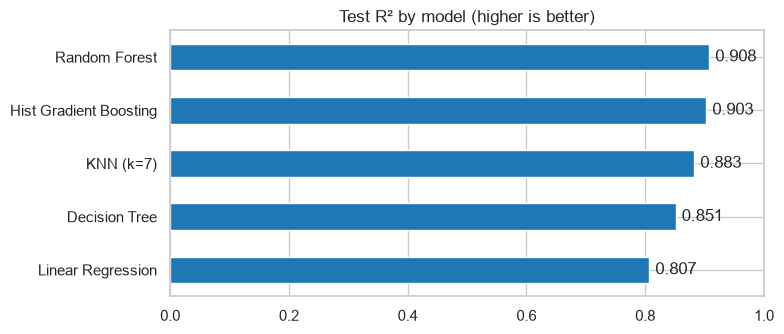

In [11]:
ax = results["Test R²"].plot(kind="barh", figsize=(8, 3.5), color="tab:blue")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title("Test R² by model (higher is better)")
for i, v in enumerate(results["Test R²"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

## 5. Best model: predicted vs. actual

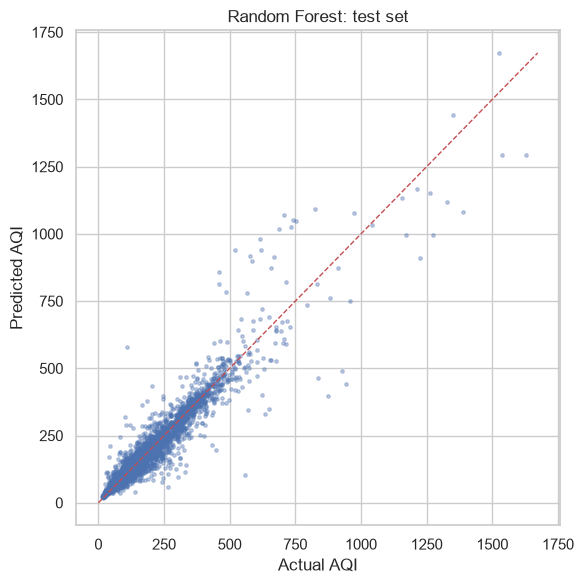

In [12]:
best_name = results.index[0]
best = models[best_name]
pred = best.predict(X_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, s=6, alpha=0.35)
lim = [0, max(y_test.max(), pred.max())]
plt.plot(lim, lim, "r--", lw=1)
plt.xlabel("Actual AQI"); plt.ylabel("Predicted AQI"); plt.title(f"{best_name}: test set")
plt.tight_layout(); plt.show()

## 6. Generalisation to unseen years (time-based split)

A random split puts days from the same week in both train and test, which flatters the score. A stricter check is to **train on 2015–2019 and test on 2020**. The 2020 data is also unusual because of the COVID-19 lockdown.

In [13]:
train_mask = df["Date"].dt.year <= 2019
time_res = pd.DataFrame({
    name: evaluate(models[name], X[train_mask], y[train_mask], X[~train_mask], y[~train_mask])
    for name in ["Random Forest", "Hist Gradient Boosting", "Linear Regression"]
}).T
print(f"train rows: {train_mask.sum()}, test rows (2020): {(~train_mask).sum()}")
time_res.round(3)

train rows: 20429, test rows (2020): 4421


,Train R²,Test R²,Test RMSE,Test MAE
Random Forest,0.976,0.905,25.668,15.920
Hist Gradient Boosting,0.938,0.912,24.768,15.705
Linear Regression,0.843,0.862,31.001,20.919


## 7. Which pollutants drive the prediction?

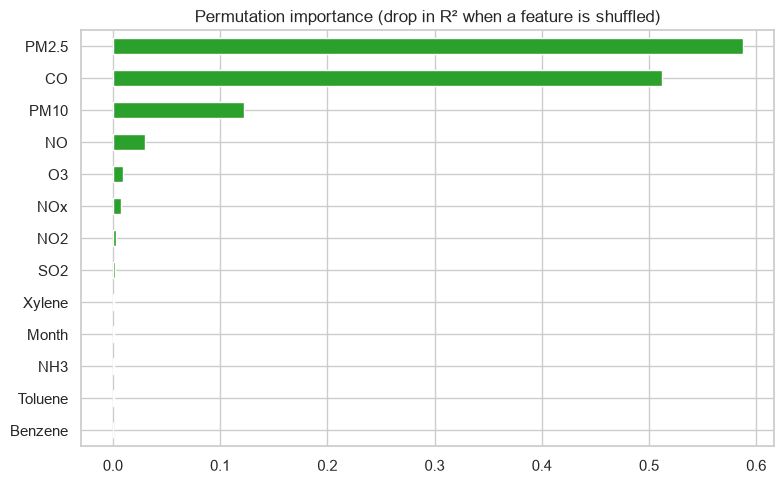

PM2.5    0.587
CO       0.512
PM10     0.122
NO       0.030
O3       0.009
dtype: float64

In [14]:
from sklearn.inspection import permutation_importance

rf = models["Random Forest"].fit(X_train, y_train)
sample = X_test.sample(3000, random_state=RANDOM_STATE)
imp = permutation_importance(rf, sample, y_test.loc[sample.index], n_repeats=5,
                             random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
importance.plot(kind="barh", figsize=(8, 5), color="tab:green")
plt.title("Permutation importance (drop in R² when a feature is shuffled)")
plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).round(3).head(5)

## 8. From AQI value to AQI category

Map predicted AQI onto the official CPCB categories and check how often the category matches the real one.

| AQI | 0–50 | 51–100 | 101–200 | 201–300 | 301–400 | 401–500 |
|---|---|---|---|---|---|---|
| Category | Good | Satisfactory | Moderate | Poor | Very Poor | Severe |

Random Forest: AQI category accuracy = 80.3%


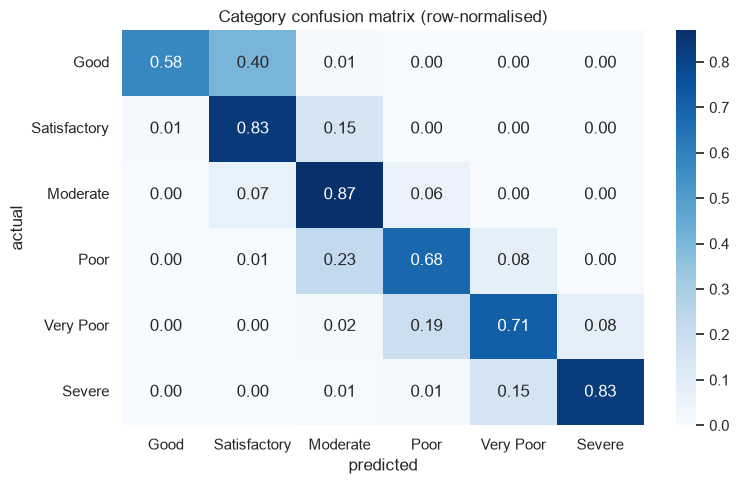

In [15]:
BINS = [-np.inf, 50, 100, 200, 300, 400, np.inf]
LABELS = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
to_bucket = lambda a: pd.cut(a, bins=BINS, labels=LABELS)

true_bucket = to_bucket(y_test)
pred_bucket = to_bucket(pd.Series(best.predict(X_test), index=y_test.index))
acc = accuracy_score(true_bucket, pred_bucket)
print(f"{best_name}: AQI category accuracy = {acc:.1%}")
cm = pd.crosstab(true_bucket, pred_bucket, rownames=["actual"], colnames=["predicted"], normalize="index")
plt.figure(figsize=(8, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues"); plt.title("Category confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()

## 9. Predict a new day

In [16]:
sample_day = pd.DataFrame([{
    "PM2.5": 120, "PM10": 210, "NO": 20, "NO2": 45, "NOx": 50, "NH3": 30, "CO": 1.4,
    "SO2": 15, "O3": 35, "Benzene": 3, "Toluene": 8, "Xylene": np.nan, "Month": 11,
}])
aqi = best.predict(sample_day)[0]
print(f"Predicted AQI: {aqi:.0f} -> {to_bucket(pd.Series([aqi]))[0]}")

Predicted AQI: 285 -> Poor


## 10. Conclusions

- Tree ensembles (Random Forest / Gradient Boosting) explain about 90 % of the variance in daily AQI on held-out data (R² ≈ 0.91, MAE ≈ 21 AQI points). Linear regression is clearly worse (R² ≈ 0.81), because AQI is a non-linear max-of-sub-indices function.
- PM2.5, CO and PM10 carry most of the signal, matching how CPCB computes AQI.
- Trained only on 2015–2019, the model still reaches R² ≈ 0.91 on 2020 (the lockdown year). It generalises to unseen time periods, not just to random days. Its absolute error is lower in 2020 because AQI levels were lower.
- **Next steps:** add lag features (yesterday's AQI) and weather data, tune hyperparameters with time-series cross-validation, and serve the model behind a small API or dashboard.